In [ ]:
import os
import pandas as pd
import numpy as np
import kagglehub

# Load del dataset
base_dir = kagglehub.dataset_download("andrewmvd/ocular-disease-recognition-odir5k")
excel_path = os.path.join(base_dir, 'full_df.csv')
image_dir = os.path.join(base_dir, 'preprocessed_images')

df = pd.read_csv(excel_path)
print(df.head())

100%|██████████| 1.62G/1.62G [01:02<00:00, 27.7MB/s]

Extracting files...


   ID  Patient Age Patient Sex Left-Fundus Right-Fundus  \
0   0           69      Female  0_left.jpg  0_right.jpg   
1   1           57        Male  1_left.jpg  1_right.jpg   
2   2           42        Male  2_left.jpg  2_right.jpg   
3   4           53        Male  4_left.jpg  4_right.jpg   
4   5           50      Female  5_left.jpg  5_right.jpg   

                            Left-Diagnostic Keywords  \
0                                           cataract   
1                                      normal fundus   
2  laser spot，moderate non proliferative retinopathy   
3                        macular epiretinal membrane   
4             moderate non proliferative retinopathy   

                Right-Diagnostic Keywords  N  D  G  C  A  H  M  O  \
0                           normal fundus  0  0  0  1  0  0  0  0   
1                           normal fundus  1  0  0  0  0  0  0  0   
2  moderate non proliferative retinopathy  0  1  0  0  0  0  0  1   
3       mild nonproliferative re

In [ ]:
import cv2
from tensorflow.keras.utils import to_categorical
import itertools

SIZE_IMG=128
images = []  # Lista per memorizzare le immagini
labels = []  # Lista per memorizzare le etichette
sex = [] # Lista per memorizzare il sesso dei soggetti

categories = [ "['C']", "['A']", "['G']"]
sex_categories = ["Male", "Female"]

# Mappatura delle etichette e del sesso
label_map = {"['C']": 0, "['A']": 1, "['G']": 2}
sex_map = {"Male": 0, "Female": 1}

# Lettura e gestione di df
for _, row in df.iterrows():
    if row['labels'] in categories:
        labels.append(label_map[row['labels']])
        sex.append(sex_map[row['Patient Sex']])
        image_path = os.path.join(image_dir, row['filename'])
        image = cv2.imread(image_path) # Lettura dell'immagine a colori
        image = cv2.resize(image, (SIZE_IMG, SIZE_IMG))  # Ridimensionamento dell'immagine
        images.append(image)

# Conversione delle liste in array numpy
images = np.array(images).astype('float32')
labels = np.array(labels)
sex = np.array(sex)

# Conteggio campioni
C = np.sum(labels == 0)
A = np.sum(labels == 1)
G = np.sum(labels == 2)

Male = np.sum(sex == 0)
Female = np.sum(sex == 1)

# Print dei valori
print(f"Numero campioni classe C: {C}")
print(f"Numero campioni classe A: {A}")
print(f"Numero campioni classe G: {G}")
print(f"Numero campioni Male: {Male}")
print(f"Numero campioni Female: {Female}")

# Creazione di una matrice di zeri per contare le combinazioni (3 classi x 2 sessi)
combinations = np.zeros((len(categories), len(sex_categories)), dtype=int)

# Conteggio delle occorrenze di ogni combinazione
for i in range(len(labels)):
    class_index = labels[i]  # Indice della classe (0, 1, 2)
    sex_index = sex[i]       # Indice del sesso (0, 1)
    combinations[class_index, sex_index] += 1

# Stampa dei risultati
for i, class_name in enumerate(categories):
    for j, sex_name in enumerate(sex_categories):
        print(f"Campioni {sex_name} appartenenti alla classe {class_name}: {combinations[i, j]} campioni")

num_classes = 3  # Numero di classi per la classificazione
labels = to_categorical(labels, num_classes=num_classes)
x_sex = sex.astype('float32')
x_sex = x_sex.reshape(-1, 1)

# Normalizzazione delle immagini
images /= 255.0
print(images.shape, labels.shape, x_sex.shape)

Numero campioni classe C: 293
Numero campioni classe A: 266
Numero campioni classe G: 284
Numero campioni Male: 432
Numero campioni Female: 411
Campioni Male appartenenti alla classe ['C']: 125 campioni
Campioni Female appartenenti alla classe ['C']: 168 campioni
Campioni Male appartenenti alla classe ['A']: 141 campioni
Campioni Female appartenenti alla classe ['A']: 125 campioni
Campioni Male appartenenti alla classe ['G']: 166 campioni
Campioni Female appartenenti alla classe ['G']: 118 campioni
(843, 128, 128, 3) (843, 3) (843, 1)


Fold esterno numero: 1
Coppia iperparametri: (16, 'adam')


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuratezza massima interna: 0.6398
Coppia iperparametri: (16, 'sgd')
Accuratezza massima interna: 0.5735
Coppia iperparametri: (32, 'adam')
Accuratezza massima interna: 0.6682
Coppia iperparametri: (32, 'sgd')
Accuratezza massima interna: 0.5024
Coppia iperparametri: (64, 'adam')
Accuratezza massima interna: 0.7333
Coppia iperparametri: (64, 'sgd')
Accuratezza massima interna: 0.4667
Miglior combinazione: (32, 'adam') con accuratezza media 0.6408
-------------------------------------------------------------)
Addestramento modello finale...
Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 153ms/step - Precision: 0.3095 - Recall: 0.0641 - accuracy: 0.3006 - f1_score: 0.2823 - loss: 1.4665
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - Precision: 0.3585 - Recall: 0.0237 - accuracy: 0.4187 - f1_score: 0.3810 - loss: 1.0684
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - Precision: 0.4983 - Recall: 0.1057 - accuracy: 0.4569 - f1_score: 0.4386 - loss: 1.0427
Epoch 4/20
20/20 ━━━━━━━━━━━━

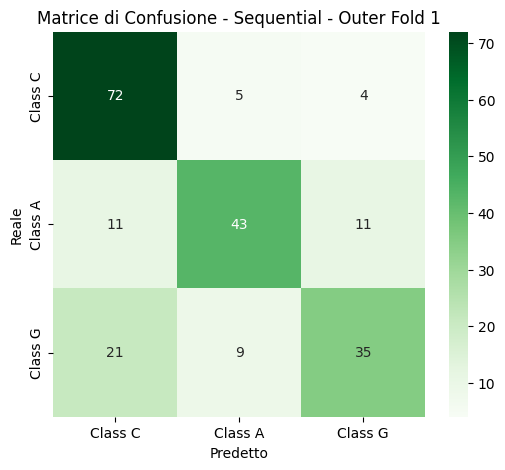

Fold esterno numero: 2
Coppia iperparametri: (16, 'adam')


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuratezza massima interna: 0.6635
Coppia iperparametri: (16, 'sgd')
Accuratezza massima interna: 0.5261
Coppia iperparametri: (32, 'adam')
Accuratezza massima interna: 0.6429
Coppia iperparametri: (32, 'sgd')
Accuratezza massima interna: 0.5118
Coppia iperparametri: (64, 'adam')
Accuratezza massima interna: 0.6445
Coppia iperparametri: (64, 'sgd')
Accuratezza massima interna: 0.5829
Miglior combinazione: (16, 'adam') con accuratezza media 0.6234
-------------------------------------------------------------)
Addestramento modello finale...
Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - Precision: 0.3435 - Recall: 0.0303 - accuracy: 0.3737 - f1_score: 0.3295 - loss: 1.1217
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - Precision: 0.5283 - Recall: 0.0836 - accuracy: 0.4885 - f1_score: 0.4779 - loss: 1.0500
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - Precision: 0.7025 - Recall: 0.2511 - accuracy: 0.5278 - f1_score: 0.5196 - loss: 0.9763
Epoch 4/20
40/40 ━━━━━━━━━━━━━

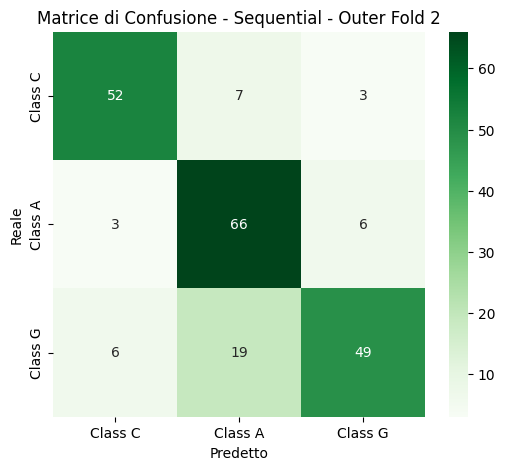

Fold esterno numero: 3
Coppia iperparametri: (16, 'adam')


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuratezza massima interna: 0.6476
Coppia iperparametri: (16, 'sgd')
Accuratezza massima interna: 0.5308
Coppia iperparametri: (32, 'adam')
Accuratezza massima interna: 0.6381
Coppia iperparametri: (32, 'sgd')
Accuratezza massima interna: 0.4929
Coppia iperparametri: (64, 'adam')
Accuratezza massima interna: 0.6762
Coppia iperparametri: (64, 'sgd')
Accuratezza massima interna: 0.4739
Miglior combinazione: (64, 'adam') con accuratezza media 0.6409
-------------------------------------------------------------)
Addestramento modello finale...
Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 261ms/step - Precision: 0.3061 - Recall: 0.0563 - accuracy: 0.3482 - f1_score: 0.3261 - loss: 1.1441
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - Precision: 0.5641 - Recall: 0.0533 - accuracy: 0.4705 - f1_score: 0.4268 - loss: 1.0466
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - Precision: 0.6917 - Recall: 0.2080 - accuracy: 0.5703 - f1_score: 0.5667 - loss: 0.9531
Epoch 4/20
10/10 ━━━━━━━━━━━━

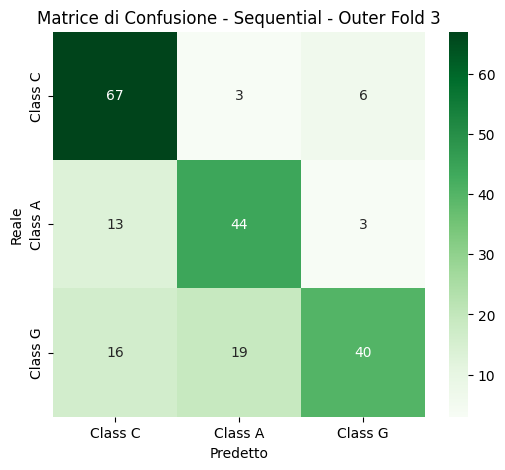

Fold esterno numero: 4
Coppia iperparametri: (16, 'adam')


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuratezza massima interna: 0.5829
Coppia iperparametri: (16, 'sgd')
Accuratezza massima interna: 0.5261
Coppia iperparametri: (32, 'adam')
Accuratezza massima interna: 0.6493
Coppia iperparametri: (32, 'sgd')
Accuratezza massima interna: 0.4882
Coppia iperparametri: (64, 'adam')
Accuratezza massima interna: 0.7014
Coppia iperparametri: (64, 'sgd')
Accuratezza massima interna: 0.5261
Miglior combinazione: (64, 'adam') con accuratezza media 0.6303
-------------------------------------------------------------)
Addestramento modello finale...
Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 226ms/step - Precision: 0.5156 - Recall: 0.0785 - accuracy: 0.4022 - f1_score: 0.3574 - loss: 1.0793
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - Precision: 0.6027 - Recall: 0.1786 - accuracy: 0.4930 - f1_score: 0.4744 - loss: 1.0033
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - Precision: 0.6076 - Recall: 0.3776 - accuracy: 0.5308 - f1_score: 0.5246 - loss: 0.9517
Epoch 4/20
10/10 ━━━━━━━━━━━━

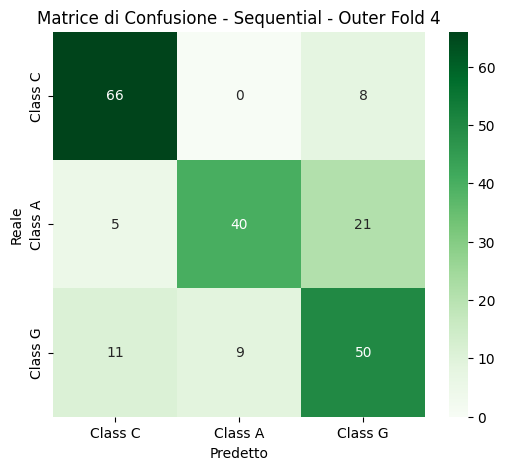

-------------------------------------------------------------)
Riepilogo dei risultati per ogni fold esterno

Accuratezza per fold esterno: [0.7109004855155945, 0.7914692163467407, 0.7156398296356201, 0.7428571581840515]
Perdita per fold esterno: [0.857987105846405, 0.6796237230300903, 0.6972340941429138, 0.6898081302642822]
Precisione per fold esterno: [0.7313432693481445, 0.795918345451355, 0.7424242496490479, 0.7711442708969116]
Recall per fold esterno: [0.6966824531555176, 0.7393364906311035, 0.6966824531555176, 0.738095223903656]
F1-score per fold esterno: [0.7034764289855957, 0.7897799611091614, 0.7085362672805786, 0.7405156493186951]
-------------------------------------------------------------)
Riepilogo dei risultati medi

Accuratezza media complessiva: 0.7402
Perdita media complessiva: 0.7312
Precisione media complessiva: 0.7602
Recall medio complessivo: 0.7177
F1-score medio complessivo: 0.7356
-------------------------------------------------------------)

=== Matrice di Co

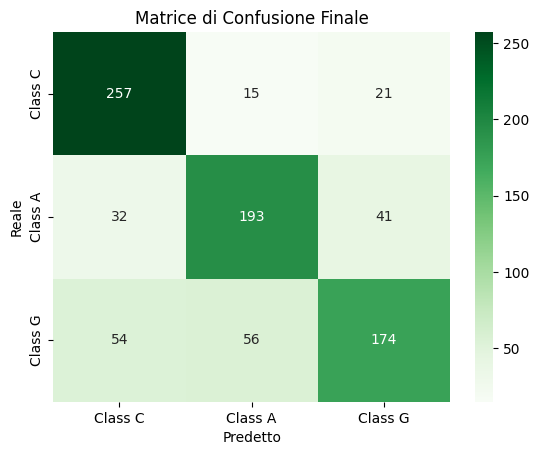

In [ ]:
import tensorflow as tf
from sklearn.model_selection import KFold
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, SGD
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


# Funzione per la creazione del modello
def create_model(input_shape):
    model = Sequential()
    model.add(Conv2D(32, (5, 5), activation='relu', input_shape=input_shape))
    model.add(MaxPooling2D((2, 2)))
    model.add(Conv2D(64, (4, 4), activation='relu'))
    model.add(MaxPooling2D((2, 2)))
    model.add(Conv2D(128, (3, 3), activation='relu'))
    model.add(MaxPooling2D((2, 2)))
    model.add(Flatten())
    model.add(Dense(128, activation='relu'))
    model.add(Dropout(0.2))
    model.add(Dense(num_classes, activation='softmax'))
    return model

# Definizione dei parametri generali
outer_fold = 4
inner_fold = 3
outer_kfold = KFold(n_splits=outer_fold, shuffle=True, random_state=42)
inner_kfold = KFold(n_splits=inner_fold, shuffle=True, random_state=42)

# Definizione della griglia di iperparametri
parameters = {
    'batch_size': [16, 32, 64],
    'optimizer': ['adam', 'sgd'],
}

# Definzione delle liste per salvare i risultati
acc_per_fold = []
loss_per_fold = []
precision_per_fold = []
recall_per_fold = []
f1_per_fold = []

# Definizione delle liste per la matrice di confusione totale
all_predictions = []
all_labels = []

INPUT_SHAPE = (SIZE_IMG, SIZE_IMG, 3)
Fold_est = 0

# Ciclo esterno
for trainOUT_index, testOUT_index in outer_kfold.split(images, labels):

    # Definizione di train e test set del ciclo esterno
    x_train_OUT, x_test_OUT = images[trainOUT_index], images[testOUT_index]
    y_train_OUT, y_test_OUT = labels[trainOUT_index], labels[testOUT_index]

    # Inizializzazione di variabili utili
    best_avg_acc = 0
    best_iperparametri = None
    Fold_est += 1
    print(f"Fold esterno numero: {Fold_est}")

    # Ciclo iperparametri
    for batch_size in parameters['batch_size']:
        for optimizer_name in parameters['optimizer']:
            inner_accuracies = [] # Array per contenere le accuratezze dei vari fold interni
            print(f"Coppia iperparametri:", (batch_size, optimizer_name))
            Fold_int = 1
            acc_massima_interna = 0

            # Ciclo interno
            for trainIN_index, valIN_index in inner_kfold.split(x_train_OUT, y_train_OUT):
                x_train_IN, x_val_IN = x_train_OUT[trainIN_index], x_train_OUT[valIN_index]
                y_train_IN, y_val_IN = y_train_OUT[trainIN_index], y_train_OUT[valIN_index]

                # Creazione del modello
                if optimizer_name == 'adam':
                    optimizer = Adam()
                else:
                    optimizer = SGD()

                model = create_model(INPUT_SHAPE)

                # Definizione dell' early stopping e del checkpoint interno
                INNER_early_stopping = EarlyStopping(monitor='accuracy', patience=3, restore_best_weights=True)
                INNER_model_checkpoint = ModelCheckpoint(f'best_model_{Fold_est}_{Fold_int}.keras', monitor='accuracy', save_best_only=True)

                # Compile e addestramento del modello
                model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
                model.fit(x_train_IN, y_train_IN, batch_size=batch_size, epochs=10, verbose=0, callbacks=[INNER_early_stopping, INNER_model_checkpoint])

                # Ripristino dei pesi della migliore epoca per l'inner fold corrente
                model.load_weights(f'best_model_{Fold_est}_{Fold_int}.keras')

                # Valutazione delle prestazioni del modello
                acc = model.evaluate(x_val_IN, y_val_IN, verbose=0)[1]
                inner_accuracies.append(acc)

                # Incremento contatore numero fold
                Fold_int += 1

            acc_massima_interna = max(inner_accuracies)
            print(f"Accuratezza massima interna: {acc_massima_interna:.4f}") # stampa l'accuratezza massima dei 3 cicli interni. non è quella per valutare i migliori iperparametri

            # Calcolo dell' accuratezza media per la combinazione di iperparametri
            avg_acc = np.mean(inner_accuracies)

            # Salvataggio dell'accuratezza se migliore tra le precedenti
            if avg_acc > best_avg_acc:
                best_avg_acc = avg_acc
                best_iperparametri = (batch_size, optimizer_name)

    print(f"Miglior combinazione: {best_iperparametri} con accuratezza media {best_avg_acc:.4f}")
    print('-------------------------------------------------------------)')
    print("Addestramento modello finale...")

    # Definisco early stopping e checkpoint esterno
    OUTER_early_stopping = EarlyStopping(monitor='accuracy', patience=5, restore_best_weights=True)
    OUTER_model_checkpoint = ModelCheckpoint(f'best_model_{Fold_est}.keras', monitor='accuracy', save_best_only=True)

    if best_iperparametri[1] == 'adam':
        final_optimizer = Adam()
    else:
        final_optimizer = SGD()

    # Creazione e addestramento del modello finale
    final_model = create_model(INPUT_SHAPE)
    final_model.compile(optimizer=final_optimizer, loss='categorical_crossentropy', metrics=['accuracy','Precision','Recall',tf.keras.metrics.F1Score(average='weighted')])
    final_model.fit(x_train_OUT, y_train_OUT, batch_size=best_iperparametri[0], epochs=20, verbose=1, callbacks=[OUTER_early_stopping, OUTER_model_checkpoint])
    print("Addestramento completato.")

    # Salvataggio dei pesi migliori
    final_model.load_weights(f'best_model_{Fold_est}.keras')

    # Valutazione del modello sul test set esterno
    scores = final_model.evaluate(x_test_OUT, y_test_OUT, verbose=0)

    # Salvataggio delle metriche
    loss_per_fold.append(scores[0])
    acc_per_fold.append(scores[1])
    precision_per_fold.append(scores[2])
    recall_per_fold.append(scores[3])
    f1_per_fold.append(scores[4])

    # Predizioni
    y_pred_OUT = np.argmax(final_model.predict(x_test_OUT), axis=1)
    y_test_OUT = np.argmax(y_test_OUT, axis=1)
    all_predictions.extend(y_pred_OUT) # Aggiunta delle predizioni alla lista all_predictions
    all_labels.extend(y_test_OUT) # Aggiunta delle etichette alla lista all_labels

    # Creazione della matrice di confusione
    cm_sequential = confusion_matrix(y_test_OUT, y_pred_OUT)

    # Visualizzazione della matrice di confusione per ogni fold
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_sequential, annot=True, fmt='d', cmap='Greens', xticklabels=['Class C', 'Class A', 'Class G'], yticklabels=['Class C', 'Class A', 'Class G'])
    plt.title(f"Matrice di Confusione - Sequential - Outer Fold {Fold_est}")
    plt.xlabel("Predetto")
    plt.ylabel("Reale")
    plt.show()

print('-------------------------------------------------------------)')
# Riepilogo dei risultati per ogni fold esterno
print("Riepilogo dei risultati per ogni fold esterno")
print(f"\nAccuratezza per fold esterno: {acc_per_fold}")
print(f"Perdita per fold esterno: {loss_per_fold}")
print(f"Precisione per fold esterno: {precision_per_fold}")
print(f"Recall per fold esterno: {recall_per_fold}")
print(f"F1-score per fold esterno: {f1_per_fold}")
print('-------------------------------------------------------------)')

acc_media_complessiva_seq=np.mean(acc_per_fold)
perdita_media_complessiva_seq=np.mean(loss_per_fold)
precisione_media_complessiva_seq=np.mean(precision_per_fold)
recall_medio_complessivo_seq=np.mean(recall_per_fold)
f1_medio_complessivo_seq=np.mean(f1_per_fold)

# Riepilogo dei risultati medi
print("Riepilogo dei risultati medi")
print(f"\nAccuratezza media complessiva: {acc_media_complessiva_seq:.4f}")
print(f"Perdita media complessiva: {perdita_media_complessiva_seq:.4f}")
print(f"Precisione media complessiva: {precisione_media_complessiva_seq:.4f}")
print(f"Recall medio complessivo: {recall_medio_complessivo_seq:.4f}")
print(f"F1-score medio complessivo: {f1_medio_complessivo_seq:.4f}")
print('-------------------------------------------------------------)')

# Matrice di confusione finale
print("\n=== Matrice di Confusione finale ===")
final_cm = confusion_matrix(all_labels, all_predictions)
sns.heatmap(final_cm, annot=True, fmt='d', cmap='Greens', xticklabels=['Class C', 'Class A', 'Class G'], yticklabels=['Class C', 'Class A', 'Class G'])
plt.title("Matrice di Confusione Finale")
plt.xlabel("Predetto")
plt.ylabel("Reale")
plt.show()

In [ ]:
from tensorflow.keras.layers import Input, concatenate
from keras.models import Model

# Modello Functional
def functional_model(input_shape, num_classes, sex_input_shape):

  #Definizione rete convoluzionale per le immagini
  img_input = Input(shape=input_shape, name='img_input')
  x = Conv2D(32, (5, 5), activation='relu')(img_input)
  x = MaxPooling2D((2, 2))(x)
  x = Conv2D(64, (4, 4), activation='relu')(x)
  x = MaxPooling2D((2, 2))(x)
  x = Conv2D(128, (3, 3), activation='relu')(x)
  x = MaxPooling2D((2, 2))(x)
  x = Flatten()(x)
  x = Dense(128, activation='relu')(x)

  #Rete per gli input di genere
  sex_input= Input(shape=sex_input_shape, name='sex_input')
  y= Dense(64, activation='relu')(sex_input)

  #Concatenazione dei due input(immagini e genere)
  concatenato = concatenate([x, y]) #gli output delle due reti vengono concatenati estraendo le info dalle immagini e dal sesso in unico vettore

  #gestione dei due input insieme
  z = Dense(128, activation='relu')(concatenato)
  z = Dropout(0.2)(z)
  output = Dense(num_classes, activation='softmax')(z)

  model = Model(inputs=[img_input, sex_input], outputs=output)
  return model


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


Fold esterno numero: 1
Coppia iperparamentri: (16, 'adam')
Accuratezza massima interna: 0.6303
Coppia iperparamentri: (16, 'sgd')
Accuratezza massima interna: 0.5024
Coppia iperparamentri: (32, 'adam')
Accuratezza massima interna: 0.6114
Coppia iperparamentri: (32, 'sgd')
Accuratezza massima interna: 0.3886
Coppia iperparamentri: (64, 'adam')
Accuratezza massima interna: 0.5782
Coppia iperparamentri: (64, 'sgd')
Accuratezza massima interna: 0.3839
Miglior combinazione: (16, 'adam') con accuratezza media 0.6171
Addestramento modello finale...
Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 68ms/step - Precision: 0.4367 - Recall: 0.0449 - accuracy: 0.3556 - f1_score: 0.3371 - loss: 1.1211
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - Precision: 0.5718 - Recall: 0.0965 - accuracy: 0.4335 - f1_score: 0.4190 - loss: 1.0627
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - Precision: 0.5407 - Recall: 0.1481 - accuracy: 0.4663 - f1_score: 0.4602 - loss: 1.0444
Epoch 4/20
40/40 ━━━━━━━━━━━━

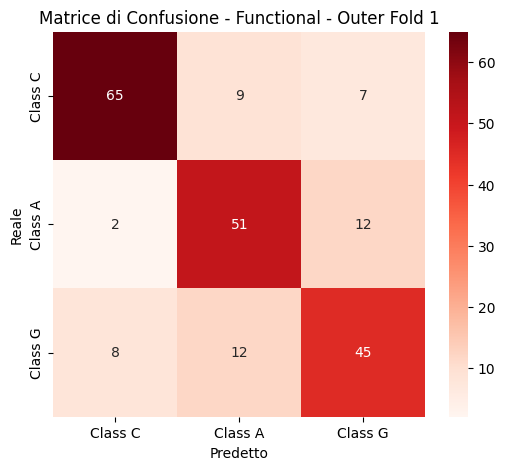

Fold esterno numero: 2
Coppia iperparamentri: (16, 'adam')


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


Accuratezza massima interna: 0.6857
Coppia iperparamentri: (16, 'sgd')
Accuratezza massima interna: 0.5829
Coppia iperparamentri: (32, 'adam')
Accuratezza massima interna: 0.6540
Coppia iperparamentri: (32, 'sgd')
Accuratezza massima interna: 0.5355
Coppia iperparamentri: (64, 'adam')
Accuratezza massima interna: 0.6524
Coppia iperparamentri: (64, 'sgd')
Accuratezza massima interna: 0.4381
Miglior combinazione: (32, 'adam') con accuratezza media 0.6297
Addestramento modello finale...
Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 191ms/step - Precision: 0.4389 - Recall: 0.0424 - accuracy: 0.3898 - f1_score: 0.3626 - loss: 1.1017
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - Precision: 0.4789 - Recall: 0.0937 - accuracy: 0.4304 - f1_score: 0.3953 - loss: 1.0778
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - Precision: 0.5775 - Recall: 0.2413 - accuracy: 0.4761 - f1_score: 0.4424 - loss: 1.0212
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - Precision: 0.6010 - Recall: 0.2920

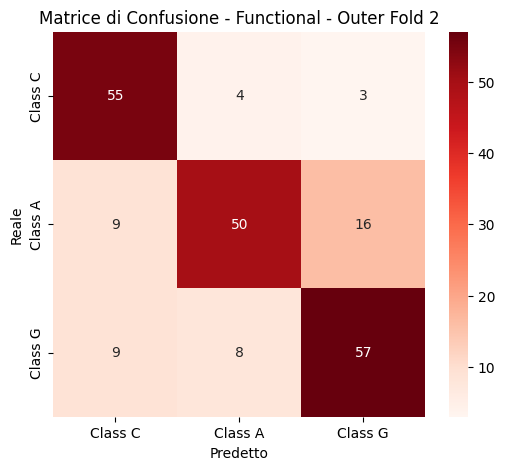

Fold esterno numero: 3
Coppia iperparamentri: (16, 'adam')


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


Accuratezza massima interna: 0.6730
Coppia iperparamentri: (16, 'sgd')
Accuratezza massima interna: 0.5213
Coppia iperparamentri: (32, 'adam')
Accuratezza massima interna: 0.6429
Coppia iperparamentri: (32, 'sgd')
Accuratezza massima interna: 0.4048
Coppia iperparamentri: (64, 'adam')
Accuratezza massima interna: 0.6730
Coppia iperparamentri: (64, 'sgd')
Accuratezza massima interna: 0.5972
Miglior combinazione: (64, 'adam') con accuratezza media 0.6455
Addestramento modello finale...
Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 544ms/step - Precision: 0.5060 - Recall: 0.0684 - accuracy: 0.4059 - f1_score: 0.3863 - loss: 1.0918
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - Precision: 0.6038 - Recall: 0.1625 - accuracy: 0.4419 - f1_score: 0.4146 - loss: 1.0516
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - Precision: 0.5578 - Recall: 0.2061 - accuracy: 0.5370 - f1_score: 0.5228 - loss: 0.9843
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - Precision: 0.6441 - Recall: 0.220

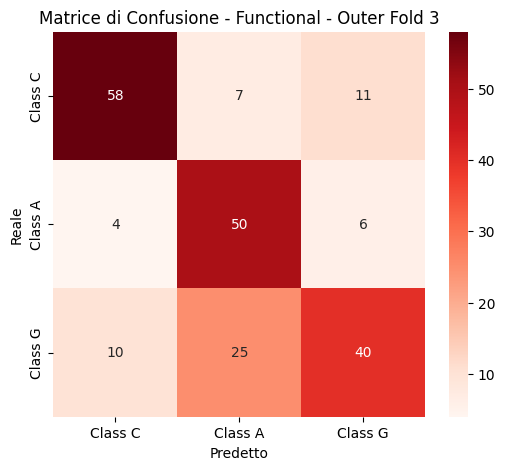

Fold esterno numero: 4
Coppia iperparamentri: (16, 'adam')


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


Accuratezza massima interna: 0.6445
Coppia iperparamentri: (16, 'sgd')
Accuratezza massima interna: 0.5687
Coppia iperparamentri: (32, 'adam')
Accuratezza massima interna: 0.6209
Coppia iperparamentri: (32, 'sgd')
Accuratezza massima interna: 0.4408
Coppia iperparamentri: (64, 'adam')
Accuratezza massima interna: 0.6161
Coppia iperparamentri: (64, 'sgd')
Accuratezza massima interna: 0.5592
Miglior combinazione: (16, 'adam') con accuratezza media 0.5719
Addestramento modello finale...
Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 92ms/step - Precision: 0.2745 - Recall: 0.0155 - accuracy: 0.3316 - f1_score: 0.3078 - loss: 1.1151
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - Precision: 0.6215 - Recall: 0.0964 - accuracy: 0.4259 - f1_score: 0.3919 - loss: 1.0548
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - Precision: 0.6135 - Recall: 0.2029 - accuracy: 0.5335 - f1_score: 0.5329 - loss: 0.9839
Epoch 4/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - Precision: 0.6801 - Recall: 0.3897 

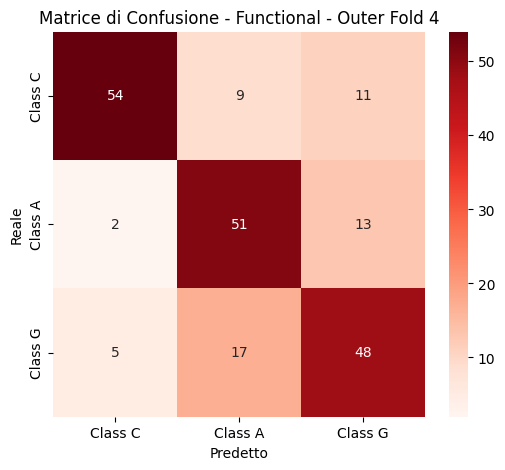

-------------------------------------------------------------)
Riepilogo dei risultati per ogni fold esterno

Accuratezza per fold esterno: [0.7630331516265869, 0.7677724957466125, 0.7014217972755432, 0.7285714149475098]
Perdita per fold esterno: [0.7725825309753418, 0.8695600032806396, 0.7184414267539978, 1.1770472526550293]
Precisione per fold esterno: [0.7850000262260437, 0.7881773114204407, 0.7373737096786499, 0.7317073345184326]
Recall per fold esterno: [0.7440758347511292, 0.758293867111206, 0.6919431090354919, 0.7142857313156128]
F1-score per fold esterno: [0.7641847133636475, 0.765417218208313, 0.697988748550415, 0.7314326167106628]
-------------------------------------------------------------)
Riepilogo dei risultati medi

Accuratezza media complessiva: 0.7402
Perdita media complessiva: 0.8844
Precisione media complessiva: 0.7606
Recall medio complessivo: 0.7271
F1-score medio complessivo: 0.7398
-------------------------------------------------------------)

=== Matrice di Co

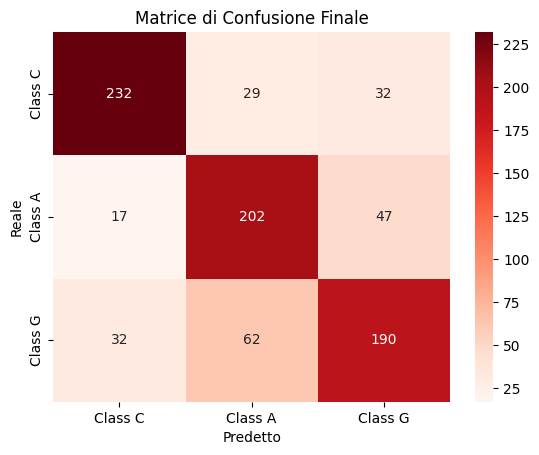

In [ ]:
# Parametri generali
outer_fold = 4
inner_fold = 3
outer_kfold = KFold(n_splits=outer_fold, shuffle=True, random_state=42)
inner_kfold = KFold(n_splits=inner_fold, shuffle=True, random_state=42)

# Griglia iperparametri
parameters = {
    'batch_size': [16, 32, 64],
    'optimizer': ['adam', 'sgd'],
}

# Variabili per salvare risultati
acc_per_fold = []
loss_per_fold = []
precision_per_fold = []
recall_per_fold = []
f1_per_fold = []

# Inizializzo array che serviranno per generare la matrice di confusione totale
all_predictions = []
all_labels = []
Fold_est = 0

# Ciclo esterno
for trainOUT_index, testOUT_index in outer_kfold.split(images, labels, x_sex):

    # definisco train e test del ciclo esterno per immagini e labels
    x_train_OUT, x_test_OUT = images[trainOUT_index], images[testOUT_index]
    y_train_OUT, y_test_OUT = labels[trainOUT_index], labels[testOUT_index]
    sex_train_OUT, sex_test_OUT = x_sex[trainOUT_index], x_sex[testOUT_index]

    # Inizializzo variabili per contenere migliore accuratezza e miglior coppia dei parametri
    best_avg_acc = 0
    best_iperparametri = None
    Fold_est += 1
    print(f"Fold esterno numero: {Fold_est}")

    # Ciclo iperparametri
    for batch_size in parameters['batch_size']:
        for optimizer_name in parameters['optimizer']:
            inner_accuracies = [] # Array per contenere le accuratezze dei vari fold interni
            print(f"Coppia iperparamentri:", (batch_size, optimizer_name))
            Fold_int = 1

            # Ciclo interno
            acc_massima_interna = 0
            for trainIN_index, valIN_index in inner_kfold.split(x_train_OUT, y_train_OUT, sex_train_OUT):
                x_train_IN, x_val_IN = x_train_OUT[trainIN_index], x_train_OUT[valIN_index]
                y_train_IN, y_val_IN = y_train_OUT[trainIN_index], y_train_OUT[valIN_index]
                sex_train_IN, sex_val_IN = sex_train_OUT[trainIN_index], sex_train_OUT[valIN_index]

                # Creazione del modello
                if optimizer_name == 'adam':
                    optimizer = Adam()
                else:
                    optimizer = SGD()

                model = functional_model(INPUT_SHAPE, num_classes, (1,))

                # definisco early stopping e moedllo di checkpoint interno
                INNER_early_stopping = EarlyStopping(monitor='accuracy', patience=3, restore_best_weights=True)
                INNER_model_checkpoint = ModelCheckpoint(f'best_model_{Fold_est}_{Fold_int}.keras', monitor='accuracy', save_best_only=True)

                # Compile e allenamento del modello
                model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
                model.fit([x_train_IN, sex_train_IN], y_train_IN, batch_size=batch_size, epochs=10, verbose=0, callbacks=[INNER_early_stopping, INNER_model_checkpoint])

                # Ripristino i migliori pesi
                model.load_weights(f'best_model_{Fold_est}_{Fold_int}.keras')

                # Valutazione del modello
                acc = model.evaluate([x_val_IN, sex_val_IN], y_val_IN, verbose=0)[1]
                inner_accuracies.append(acc)

                Fold_int += 1

            acc_massima_interna = max(inner_accuracies)
            print(f"Accuratezza massima interna: {acc_massima_interna:.4f}") # Stampa dell'accuratezza massima dei 3 cicli interni. non è quella per valutare i migliori iperparametri

            # Calcola accuratezza media
            avg_acc = np.mean(inner_accuracies)
            if avg_acc > best_avg_acc: #salva iperparametri se l'accuratezza media della coppia è la migliore tra quelle già calcolate
                best_avg_acc = avg_acc
                best_iperparametri = (batch_size, optimizer_name)


    print(f"Miglior combinazione: {best_iperparametri} con accuratezza media {best_avg_acc:.4f}")
    print("Addestramento modello finale...")

    # Addestramento modello finale
    OUTER_early_stopping = EarlyStopping(monitor='accuracy', patience=5, restore_best_weights=True)
    OUTER_model_checkpoint = ModelCheckpoint(f'best_model_{Fold_est}.keras', monitor='accuracy', save_best_only=True)

    if best_iperparametri[1] == 'adam':
        final_optimizer = Adam()
    else:
        final_optimizer = SGD()

    final_model = functional_model(INPUT_SHAPE, num_classes, (1,))
    final_model.compile(optimizer=final_optimizer, loss='categorical_crossentropy', metrics=['accuracy','Precision','Recall',tf.keras.metrics.F1Score(average='weighted')])
    final_model.fit([x_train_OUT, sex_train_OUT], y_train_OUT,  batch_size=best_iperparametri[0], epochs=20, verbose=1, callbacks=[OUTER_early_stopping, OUTER_model_checkpoint])
    print("Addestramento completato.")

    # Load dei pesi migliori
    final_model.load_weights(f'best_model_{Fold_est}.keras')

    # Valutazione sul test set esterno
    scores = final_model.evaluate([x_test_OUT, sex_test_OUT], y_test_OUT, verbose=0)
    loss_per_fold.append(scores[0])
    acc_per_fold.append(scores[1])
    precision_per_fold.append(scores[2])
    recall_per_fold.append(scores[3])
    f1_per_fold.append(scores[4])

    #Predizioni
    y_pred_OUT = np.argmax(final_model.predict([x_test_OUT,sex_test_OUT]), axis=1) #predict restituisce la probabilità previste per ciascuna classe per ogni campione di test,argmax trova l indice con la probabilità piu alta
    y_test_OUT = np.argmax(y_test_OUT, axis=1)
    all_predictions.extend(y_pred_OUT) # aggiunge tutte le predizioni alla lista all_predictions
    all_labels.extend(y_test_OUT) # aggiunge le etichette reali alla lista all_labels

    # Matrice di confusione
    cm_functional = confusion_matrix(y_test_OUT, y_pred_OUT)

    # Visualizzazione della matrice di confusione per ogni fold
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_functional, annot=True, fmt='d', cmap='Reds', xticklabels=['Class C', 'Class A', 'Class G'], yticklabels=['Class C', 'Class A', 'Class G'])
    plt.title(f"Matrice di Confusione - Functional - Outer Fold {Fold_est}")
    plt.xlabel("Predetto")
    plt.ylabel("Reale")
    plt.show()

print('-------------------------------------------------------------)')
# Riepilogo dei risultati per ogni fold esterno
print("Riepilogo dei risultati per ogni fold esterno")
print(f"\nAccuratezza per fold esterno: {acc_per_fold}")
print(f"Perdita per fold esterno: {loss_per_fold}")
print(f"Precisione per fold esterno: {precision_per_fold}")
print(f"Recall per fold esterno: {recall_per_fold}")
print(f"F1-score per fold esterno: {f1_per_fold}")

print('-------------------------------------------------------------)')

acc_media_complessiva_fun=np.mean(acc_per_fold)
perdita_media_complessiva_fun=np.mean(loss_per_fold)
precisione_media_complessiva_fun=np.mean(precision_per_fold)
recall_medio_complessivo_fun=np.mean(recall_per_fold)
f1_medio_complessivo_fun=np.mean(f1_per_fold)

# Riepilogo dei risultati medi
print("Riepilogo dei risultati medi")
print(f"\nAccuratezza media complessiva: {acc_media_complessiva_fun:.4f}")
print(f"Perdita media complessiva: {perdita_media_complessiva_fun:.4f}")
print(f"Precisione media complessiva: {precisione_media_complessiva_fun:.4f}")
print(f"Recall medio complessivo: {recall_medio_complessivo_fun:.4f}")
print(f"F1-score medio complessivo: {f1_medio_complessivo_fun:.4f}")
print('-------------------------------------------------------------)')

# Matrice di confusione finale
print("\n=== Matrice di Confusione finale ===")
final_cm = confusion_matrix(all_labels, all_predictions)
sns.heatmap(final_cm, annot=True, fmt='d', cmap='Reds', xticklabels=['Class C', 'Class A', 'Class G'], yticklabels=['Class C', 'Class A', 'Class G'])
plt.title("Matrice di Confusione Finale")
plt.xlabel("Predetto")
plt.ylabel("Reale")
plt.show()

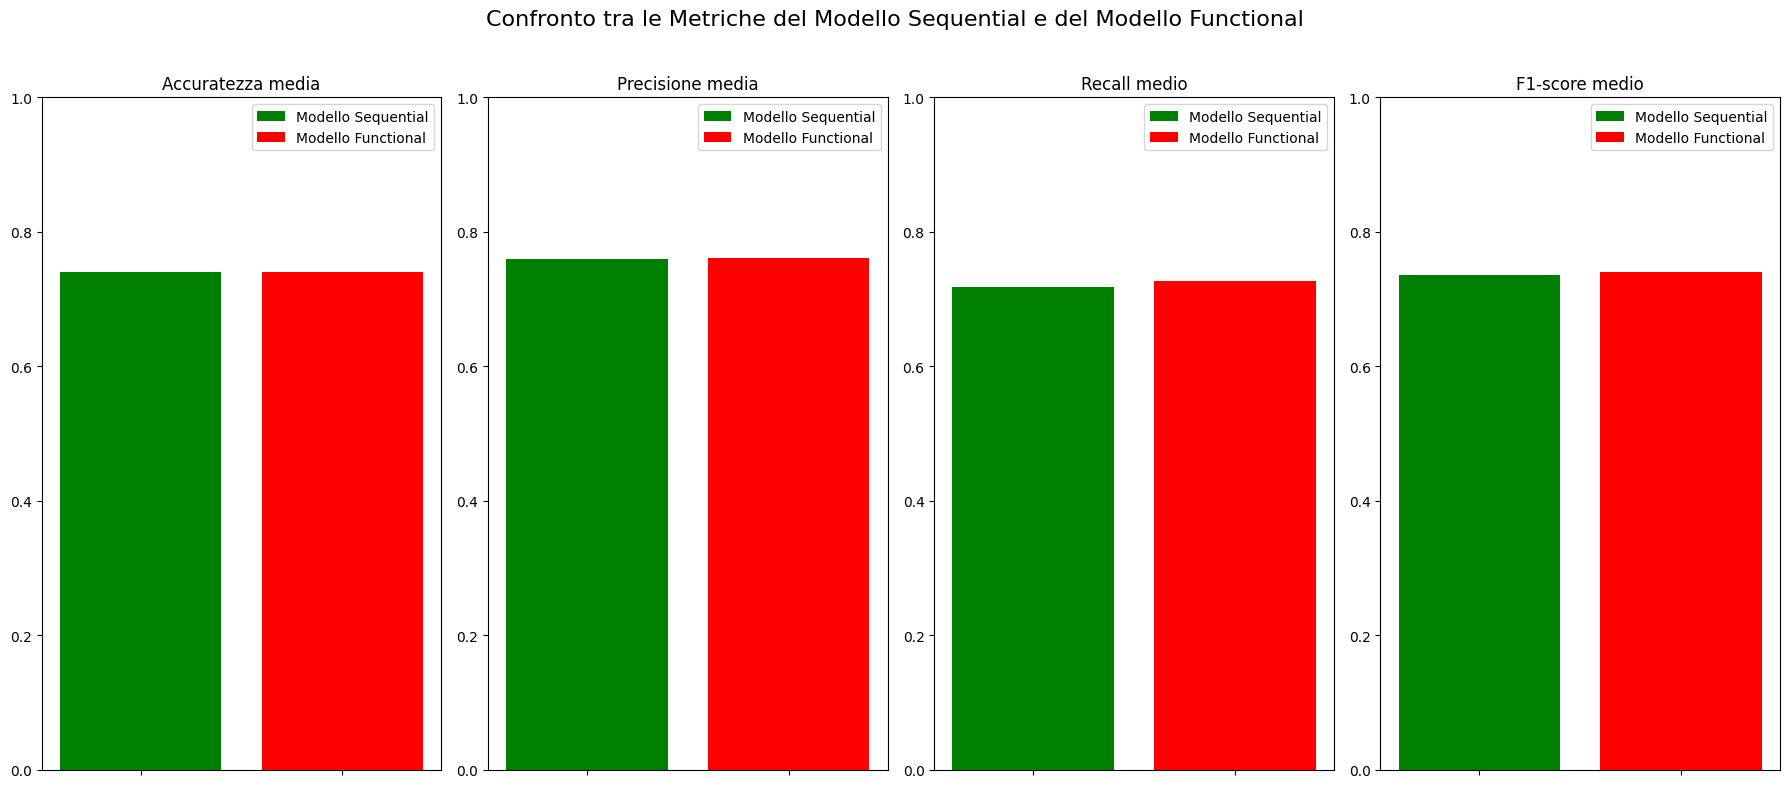

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Lista delle etichette per le metriche
metriche = ['Accuratezza media','Precisione media', 'Recall medio', 'F1-score medio' ]
# Lista dei valori delle metriche per il modello sequential
metriche_seq = [acc_media_complessiva_seq, precisione_media_complessiva_seq, recall_medio_complessivo_seq, f1_medio_complessivo_seq]
# Lista dei valori delle metriche per il modello functional
metriche_fun = [acc_media_complessiva_fun, precisione_media_complessiva_fun, recall_medio_complessivo_fun, f1_medio_complessivo_fun]

# Creazione dei subplot (1 riga, 4 colonne)
fig, axes = plt.subplots(1, 4, figsize =(18,8))

# Creazione grafici
for i, metric in enumerate(metriche):
    seq_metrica = metriche_seq[i]
    fun_metrica = metriche_fun[i]

    bars= axes[i].bar(['Modello Sequential', 'Modello Functional'],[seq_metrica, fun_metrica], color=['green', 'red'])
    axes[i].set_title(f'{metric}') # Titolo del subplot
    axes[i].set_ylim(0, 1)
    axes[i].set_xticklabels([]) # Eliminazione visualizzazione etichetta asse x
    axes[i].legend([bars[0], bars[1]], ['Modello Sequential', 'Modello Functional'], loc='upper right')

plt.suptitle('Confronto tra le Metriche del Modello Sequential e del Modello Functional', fontsize=16)
plt.show()